# Airline Review Analysis - Notebook 7: Validation

In Notebook 6 the system produced a sentiment for each topic in each review. But how do I know these scores are any good? I have no hand-labelled data, and I do not want to label reviews by hand.

The dataset already contains something I can check against: passengers gave their own **1 to 5 star rating** for seat comfort, cabin staff, food, entertainment, ground service, WiFi and value for money. If my topic scores are meaningful, then a passenger who writes negatively about the seat should also give a low seat rating.

Important: I only use the **test reviews** (the 20% that the model never saw during training), so the check is fair.

Input: `data/reviews_preprocessed.csv`, `data/aspect_reviews.csv`, `models/sentiment_model.joblib`

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_style("whitegrid")

df = pd.read_csv("data/reviews_preprocessed.csv")
aspect_reviews = pd.read_csv("data/aspect_reviews.csv")
saved = joblib.load("models/sentiment_model.joblib")
tfidf, model = saved["tfidf"], saved["model"]

# only the test reviews
test_scores = aspect_reviews[aspect_reviews["split"] == "test"]
print("test reviews:", test_scores["review_id"].nunique(), "| review-topic scores:", len(test_scores))

# our topic -> the passenger's own rating for the same thing
rating_columns = {"seat": "seat_comfort", "cabin_crew": "cabin_staff_service", "food": "food__beverages",
                  "entertainment": "inflight_entertainment", "ground_staff": "ground_service",
                  "wifi": "wifi__connectivity", "value_fees": "value_for_money"}


def get_data(topic):
    # topic scores of the test reviews, together with the passenger's rating for that topic
    part = test_scores[test_scores["topic"] == topic].copy()
    part["rating"] = df.loc[part["review_id"], rating_columns[topic]].values
    part["overall"] = df.loc[part["review_id"], "over_all_rating"].values
    return part.dropna(subset=["rating"])

test reviews: 12507 | review-topic scores: 46421


## 2. Test 1: do the scores follow the passengers' ratings?

I measure this with the **Spearman correlation**. It goes from -1 to +1: +1 means that a higher score always goes with a higher rating, 0 means no relation. I compare the two sentiment methods from Notebook 6: the learned lexicon and VADER.

In [2]:
rows = []
for topic in rating_columns:
    part = get_data(topic)
    rows.append({"topic": topic, "reviews": len(part),
                 "learned lexicon": part["learned"].corr(part["rating"], method="spearman"),
                 "VADER": part["vader"].corr(part["rating"], method="spearman")})

test1 = pd.DataFrame(rows).set_index("topic").round(2)
test1

,reviews,learned lexicon,VADER
topic,,,
seat,5253,0.66,0.53
cabin_crew,4840,0.69,0.62
food,5736,0.69,0.59
entertainment,2627,0.66,0.52
ground_staff,3561,0.51,0.38
wifi,455,0.71,0.54
value_fees,3894,0.57,0.33


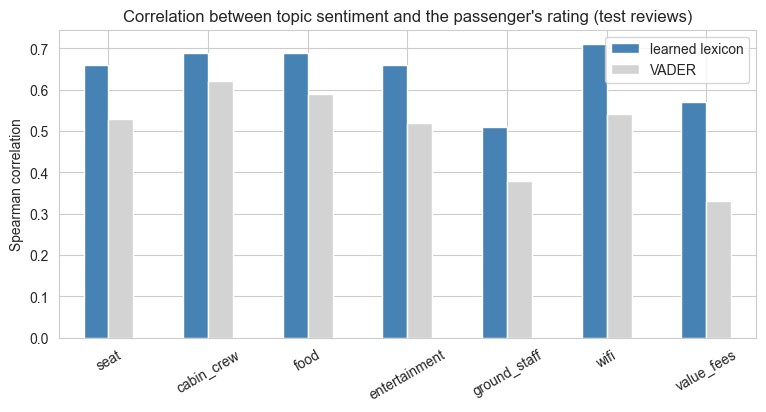

average correlation - learned lexicon: 0.64
average correlation - VADER: 0.5


In [3]:
test1[["learned lexicon", "VADER"]].plot(kind="bar", figsize=(9, 4), color=["steelblue", "lightgrey"])
plt.title("Correlation between topic sentiment and the passenger's rating (test reviews)")
plt.ylabel("Spearman correlation")
plt.xlabel("")
plt.xticks(rotation=30)
plt.show()

print("average correlation - learned lexicon:", round(test1["learned lexicon"].mean(), 2))
print("average correlation - VADER:", round(test1["VADER"].mean(), 2))

The learned lexicon is better than VADER for every topic (average 0.64 against 0.50). The gap is biggest for value / fees (0.57 against 0.33) and WiFi (0.71 against 0.54). So the learned lexicon is the method I use for the rest of the project.

## 3. Test 2: what do passengers rate when we say negative, neutral or positive?

For each of our labels, I calculate the average rating (1 to 5) that the passengers gave.

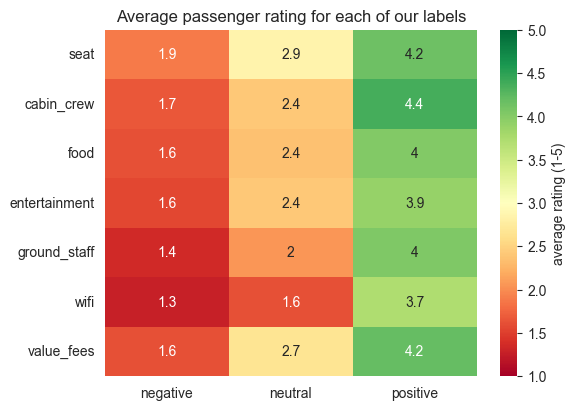

In [4]:
rows = []
for topic in rating_columns:
    part = get_data(topic)
    averages = part.groupby("label")["rating"].mean()
    rows.append({"topic": topic, "negative": averages["negative"], "neutral": averages["neutral"], "positive": averages["positive"]})

test2 = pd.DataFrame(rows).set_index("topic").round(2)

plt.figure(figsize=(6, 4.5))
sns.heatmap(test2, annot=True, cmap="RdYlGn", vmin=1, vmax=5, cbar_kws={"label": "average rating (1-5)"})
plt.title("Average passenger rating for each of our labels")
plt.ylabel("")
plt.show()

For every topic the order is right: passengers whose text we labelled negative gave about 1.3 to 1.9 stars, the neutral ones about 1.6 to 2.9 and the positive ones about 3.7 to 4.4 stars.

## 4. Test 3: agreement on the clear cases

Take only the passengers who were clearly unhappy (1 or 2 stars) or clearly happy (4 or 5 stars), and the reviews where we gave a negative or positive label. How often do the label and the rating agree?

In [5]:
rows = []
for topic in rating_columns:
    part = get_data(topic)
    part = part[part["rating"].isin([1, 2, 4, 5]) & (part["label"] != "neutral")]
    agree = ((part["label"] == "positive") == (part["rating"] >= 4)).mean()
    rows.append({"topic": topic, "cases": len(part), "agreement": round(agree * 100, 1)})

test3 = pd.DataFrame(rows).set_index("topic")
test3

,cases,agreement
topic,,
seat,3102,90.1
cabin_crew,3440,91.5
food,3473,89.4
entertainment,1679,87.0
ground_staff,2566,93.0
wifi,286,79.4
value_fees,2727,90.1


The agreement is about 87% to 93% for most topics. WiFi is lower (79%), but it only has 286 cases, so it is less certain.

## 5. Test 4: is it just the overall mood?

There is a problem with the tests above. A passenger who is unhappy overall tends to give **low ratings to everything**, even to things that were fine. So even a score for the whole review would correlate with every single rating. Let me check this by using the whole-review score from Notebook 4 as a comparison.

In [6]:
test_ids = test_scores["review_id"].unique()
whole_review = pd.Series(model.predict_proba(tfidf.transform(df.loc[test_ids, "review_text"]))[:, 1], index=test_ids)

rows = []
for topic in rating_columns:
    part = get_data(topic)
    part["whole"] = whole_review.loc[part["review_id"]].values
    rows.append({"topic": topic,
                 "topic score": part["learned"].corr(part["rating"], method="spearman"),
                 "whole review score": part["whole"].corr(part["rating"], method="spearman")})
pd.DataFrame(rows).set_index("topic").round(2)

,topic score,whole review score
topic,,
seat,0.66,0.72
cabin_crew,0.69,0.75
food,0.69,0.71
entertainment,0.66,0.65
ground_staff,0.51,0.63
wifi,0.71,0.66
value_fees,0.57,0.76


The whole-review score correlates with the ratings about as strongly (and for most topics even more strongly), even though it knows nothing about the specific topic. So the correlations above are partly caused by the overall mood and do not prove that the topic scores are specific.

A fairer question is: **after taking the overall rating into account, does the topic score still tell me something about the rating for that topic?** This is called a *partial correlation*. I remove the part of both values that can be explained by the passenger's overall rating (1 to 10), and then correlate what is left.

In [7]:
def partial_corr(x, y, control):
    x, y, control = x.rank(), y.rank(), control.rank()
    x_left = x - np.polyval(np.polyfit(control, x, 1), control)      # what the overall rating cannot explain
    y_left = y - np.polyval(np.polyfit(control, y, 1), control)
    return np.corrcoef(x_left, y_left)[0, 1]


rows = []
for topic in rating_columns:
    part = get_data(topic).dropna(subset=["overall"])
    part["whole"] = whole_review.loc[part["review_id"]].values
    rows.append({"topic": topic, "reviews": len(part),
                 "topic score": partial_corr(part["learned"], part["rating"], part["overall"]),
                 "whole review score": partial_corr(part["whole"], part["rating"], part["overall"])})

test4 = pd.DataFrame(rows).set_index("topic").round(2)
test4

,reviews,topic score,whole review score
topic,,,
seat,5238,0.30,0.16
cabin_crew,4830,0.35,0.19
food,5724,0.36,0.15
entertainment,2619,0.45,0.18
ground_staff,3561,0.21,0.22
wifi,455,0.53,0.25
value_fees,3888,0.20,0.26


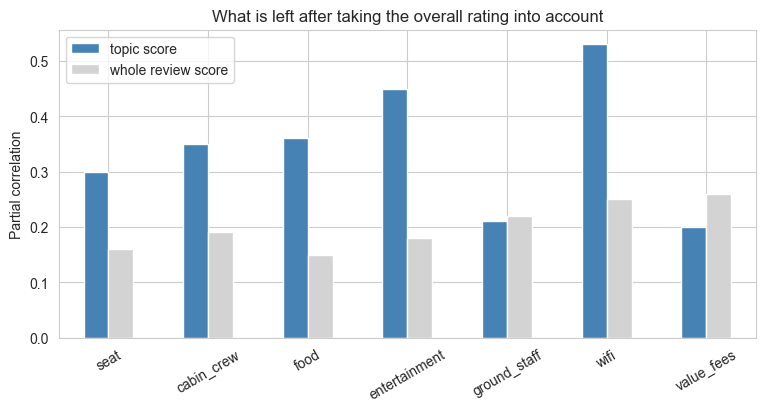

In [8]:
test4[["topic score", "whole review score"]].plot(kind="bar", figsize=(9, 4), color=["steelblue", "lightgrey"])
plt.title("What is left after taking the overall rating into account")
plt.ylabel("Partial correlation")
plt.xlabel("")
plt.xticks(rotation=30)
plt.show()

This is the most important result of the validation:

- For **seat, cabin crew, food, entertainment and WiFi** the topic score still has a clear relation with the specific rating (0.30 to 0.53), much more than the whole-review score (0.15 to 0.25). So these topic scores carry real information about that topic.
- For **ground staff and value / fees** the topic score is not better than the whole-review score (0.21 and 0.20 against 0.22 and 0.26). For these two topics my word lists are not specific enough: "customer service" and words like "price" or "money" appear in many kinds of sentences, so the score mostly reflects the general mood.

## 6. Conclusion

| Topic | How far I trust the topic score |
|---|---|
| Cabin crew, food, seat, entertainment | Good (consistent in all four tests) |
| WiFi | Good, but based on few reviews (only 5% of reviews mention it) |
| Ground staff, value / fees | Weaker: they agree with the ratings, but mostly reflect the overall mood |

For the other topics (delay, cancellation, baggage, boarding, refund, communication) there is no matching rating in the dataset, so I cannot check them in this way. I will interpret those results more carefully and use the recommendation of the passenger (the `recommended` column) as a second check in the next notebook.

## Summary

- The topic scores were tested on the test reviews only, using the passengers' own ratings. No manual labelling was needed.
- The learned lexicon beat VADER on all seven topics (average correlation 0.64 against 0.50), and the labels agree with clear ratings in about 87% to 93% of cases.
- Because passengers' ratings are strongly linked to their overall mood, I also used a partial correlation. The topic scores add real information for five of the seven topics, and are weaker for ground staff and value / fees.

Next notebook: business insights, which uses the topic sentiments to find the biggest problems and compare airlines, years and passenger groups.